<a href="https://colab.research.google.com/github/Mostafizur5291/0152310005101016_Mostafizur-OOP-Assignment/blob/main/Copy_of_DMining_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cluster assignments for 3 clusters: [3 3 1 2 3 2 1 1 1 1 1 1 3 1 1 1 2 3 1 3]


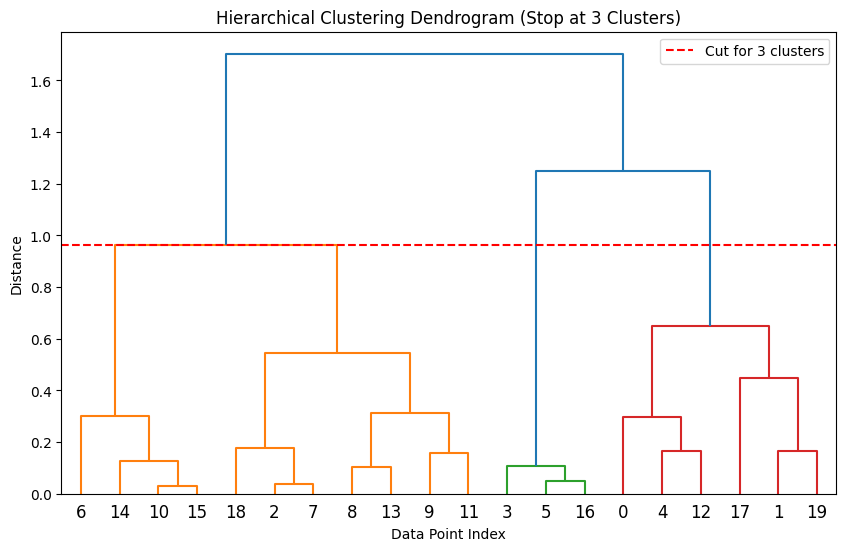

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# 1. Load your 2D iris data (20 points, 2 features)
# data = np.loadtxt('iris_2d_20.txt', delimiter=',')
# For demonstration, generating 20 random 2D points:
np.random.seed(42)
data = np.random.rand(20, 2)

# 1a. Perform hierarchical clustering
# Using 'ward' linkage. Change to 'single', 'complete', or 'average' if required by your course.
Z = linkage(data, method='ward')

# Get cluster assignments for exactly 3 clusters
clusters = fcluster(Z, 3, criterion='maxclust')
print("Cluster assignments for 3 clusters:", clusters)

# 1b. Draw the tree (Dendrogram)
plt.figure(figsize=(10, 6))
dendrogram(Z, leaf_font_size=12)
plt.title('Hierarchical Clustering Dendrogram (Stop at 3 Clusters)')
plt.xlabel('Data Point Index')
plt.ylabel('Distance')

# Draw a horizontal line to indicate the cut for 3 clusters
# To get 3 clusters from 20 points, we make 17 merges.
# The cut threshold is the distance of the 17th merge (index 16).
cut_threshold = Z[16, 2]
plt.axhline(y=cut_threshold, color='r', linestyle='--', label='Cut for 3 clusters')
plt.legend()
plt.show()

In [ ]:
import numpy as np
import random

# ==========================================
# Task 3: Load Data
# ==========================================
def load_data(filename):
    # First column is index, next 50 are features (comma separated)
    data = np.loadtxt(filename, delimiter=',')
    indices = data[:, 0].astype(int)
    features = data[:, 1:]
    return indices, features

# ==========================================
# Task 4a & 5: Initialization Functions
# ==========================================
def initialize_centroids_simple(data, K):
    """Randomly select K points from the sampled data."""
    indices = random.sample(range(len(data)), K)
    return data[indices].copy()

def initialize_centroids(data, K):
    """Initialize centroids based on min/max feature values (Task 5)."""
    min_vals = np.min(data, axis=0)
    max_vals = np.max(data, axis=0)
    diff = max_vals - min_vals

    centroids = np.zeros((K, data.shape[1]))
    for j in range(K):
        for i in range(data.shape[1]):
            centroids[j, i] = min_vals[i] + diff[i] * random.uniform(1e-5, 1)
    return centroids

# ==========================================
# Task 1, 4b, 4c: K-Means Algorithm
# ==========================================
def kmeans(data, K, init_func):
    N = len(data)
    centroids = init_func(data, K)
    prev_J = float('inf')

    while True:
        # Assign points to nearest centroid
        # Broadcasting to compute distances: (N, 1, D) - (1, K, D) -> (N, K, D)
        dists = np.linalg.norm(data[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
        labels = np.argmin(dists, axis=1)

        # Task 4b: Count number of points assigned to each cluster
        counts = np.zeros(K, dtype=int)
        for k in range(K):
            counts[k] = np.sum(labels == k)

        # Calculate clustering objective J
        J = 0.0
        for i in range(N):
            J += np.sum((data[i] - centroids[labels[i]])**2)

        # Task 4c: Termination criteria |J - Jprev| <= 10^-5 * J
        if prev_J != float('inf') and abs(J - prev_J) <= 1e-5 * J:
            break
        prev_J = J

        # Update centroids
        new_centroids = np.zeros_like(centroids)
        for k in range(K):
            mask = (labels == k)
            if counts[k] > 0:
                new_centroids[k] = np.mean(data[mask], axis=0)
            else:
                # If a cluster is empty, keep the old centroid to avoid division by zero
                new_centroids[k] = centroids[k]
        centroids = new_centroids

    return centroids, labels, counts, J

# ==========================================
# Main Execution
# ==========================================
if __name__ == "__main__":
    # Create a dummy 'data0.txt' file for demonstration
    # In a real scenario, you would ensure 'data0.txt' is available or provide the correct path.
    dummy_data = np.random.rand(100, 51) # 100 points, 1 index column + 50 features
    dummy_data[:, 0] = np.arange(100) # Populate index column
    np.savetxt('data0.txt', dummy_data, delimiter=',')

    # Load data
    orig_indices, features = load_data('data0.txt')

    # Sample a fixed number of points randomly (e.g., 1000 points)
    num_samples = min(1000, len(features))
    sampled_idx = random.sample(range(len(features)), num_samples)
    sampled_features = features[sampled_idx]
    sampled_orig_indices = orig_indices[sampled_idx]

    K = 5 # Define number of clusters (Adjust K based on your specific assignment requirements)

    # --- Task 4: Simple Initialization ---
    print("Running K-Means with Simple Random Initialization...")
    centroids1, labels1, counts1, J1 = kmeans(sampled_features, K, initialize_centroids_simple)

    # Task 4d: Save outputs
    np.savetxt('out1.txt', centroids1, delimiter=',')
    with open('out2.txt', 'w') as f:
        for idx, label in zip(sampled_orig_indices, labels1):
            f.write(f"{idx},{label}\n")

    # --- Task 5 & 6: Min-Max Uniform Initialization ---
    print("Running K-Means with Min-Max Uniform Initialization...")
    centroids2, labels2, counts2, J2 = kmeans(sampled_features, K, initialize_centroids)

    # Task 6: Save outputs (using out3 and out4)
    np.savetxt('out3.txt', centroids2, delimiter=',')
    with open('out4.txt', 'w') as f:
        for idx, label in zip(sampled_orig_indices, labels2):
            f.write(f"{idx},{label}\n")

    # --- Task 7: Compare Outputs ---
    print("\n--- Comparison of Initializations ---")
    print(f"Simple Init Final Objective (J): {J1:.4f}")
    print(f"Min-Max Init Final Objective (J): {J2:.4f}")
    print(f"Simple Init Cluster Counts: {counts1}")
    print(f"Min-Max Init Cluster Counts: {counts2}")

Running K-Means with Simple Random Initialization...
Running K-Means with Min-Max Uniform Initialization...

--- Comparison of Initializations ---
Simple Init Final Objective (J): 372.9197
Min-Max Init Final Objective (J): 373.6387
Simple Init Cluster Counts: [26 12 15 28 19]
Min-Max Init Cluster Counts: [18 10 26 17 29]
